# Matrices and tensors in AI

## Numbers in AI come in groups

An AI model never sees a house, a photo or a sentence directly. It only sees **numbers**:

- a house becomes its area, number of rooms and age;
- a photo becomes the brightness of each of its pixels;
- a sentence becomes a list of numbers that represent its words.

These numbers are organised into groups with a fixed structure: scalars, vectors, matrices and, in general, **tensors**. In Python we work with them through **NumPy**, the standard **library** (a collection of ready-made code that a program can import and use) for numerical computing. Its central object is the **array**: a grid of numbers, all of the same type.

## From single numbers to tensors

A **scalar** is a single number, such as a temperature: `21.5`.

A **vector** is an ordered list of numbers. For example, a house described by three **features** (measurable properties): area in m², number of rooms, and age in years. Every NumPy array has an `ndim` (its number of **dimensions**, that is, how many indices you need to pick out one number) and a `shape` (its size along each dimension):

In [ ]:
import numpy as np

house = np.array([120.0, 3.0, 15.0])
house.ndim, house.shape

(1, (3,))

A **matrix** is a table of numbers with rows and columns: two dimensions. A dataset of several houses is a matrix with one row per house and one column per feature. This is the standard layout for tabular data in machine learning.

In [ ]:
houses = np.array([
    [120.0, 3.0, 15.0],
    [80.0, 2.0, 30.0],
    [200.0, 5.0, 2.0],
    [95.0, 3.0, 8.0],
])
houses.ndim, houses.shape

(2, (4, 3))

A black-and-white image is also a matrix: each number is the brightness of one pixel, from 0 (black) to 255 (white). This 7 × 7 matrix draws an X:

In [ ]:
image_of_an_x = np.zeros((7, 7))
for position in range(7):
    image_of_an_x[position, position] = 255
    image_of_an_x[position, 6 - position] = 255
image_of_an_x

array([[255.,   0.,   0.,   0.,   0.,   0., 255.],
       [  0., 255.,   0.,   0.,   0., 255.,   0.],
       [  0.,   0., 255.,   0., 255.,   0.,   0.],
       [  0.,   0.,   0., 255.,   0.,   0.,   0.],
       [  0.,   0., 255.,   0., 255.,   0.,   0.],
       [  0., 255.,   0.,   0.,   0., 255.,   0.],
       [255.,   0.,   0.,   0.,   0.,   0., 255.]])

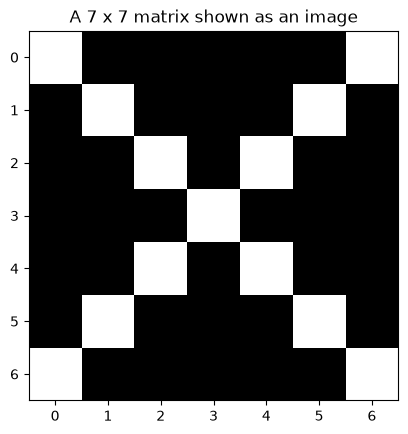

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(image_of_an_x, cmap="gray")
plt.title("A 7 x 7 matrix shown as an image")
plt.show()

A **tensor** is the general case: a grid of numbers with *any* number of dimensions. AI constantly needs more than two:

- A **colour image** stores three numbers per pixel (red, green and blue), so its shape is *height × width × 3*.
- A **batch** is a group of examples processed together, because processing many at once is much more efficient. A batch of 32 colour images of 224 × 224 pixels has shape *32 × 224 × 224 × 3*: four dimensions and almost 5 million numbers.

In [ ]:
image_batch = np.zeros((32, 224, 224, 3))
image_batch.ndim, image_batch.shape, image_batch.size

(4, (32, 224, 224, 3), 4816896)

**Array or tensor?** They are two names for the same idea. NumPy calls its grids of numbers *arrays*; the deep-learning libraries PyTorch and TensorFlow call theirs *tensors*. In this sense, scalars, vectors and matrices are just tensors with 0, 1 and 2 dimensions. NumPy can even store a single number as a 0-dimensional array, so that everything in NumPy has an `ndim` and a `shape`:

In [ ]:
temperature = np.array(21.5)
temperature.ndim, temperature.shape

(0, ())

What a PyTorch *tensor* adds to a NumPy *array* is not a different kind of data but two abilities: it can live in the memory of a graphics card, so the GPU can compute with it (notebook 05), and it can keep track of the operations applied to it, which is how models are trained. (Mathematicians use the word "tensor" for a more specific object; in AI it simply means a grid of numbers with any number of dimensions.)

All the values in an array share one type, its **dtype**, for example 64-bit decimal numbers (`float64`).

→ Deep dive: [Numbers and memory](deep-dives/numbers_and_memory.ipynb) explains how those numbers are stored, and why the way they are stored matters for speed.

## Why not use Python lists?

A list of lists can store the same numbers, but lists are not designed for mathematics. With lists, `+` *joins* two lists; with arrays, it *adds* the numbers position by position:

In [ ]:
[1, 2, 3] + [10, 20, 30]

[1, 2, 3, 10, 20, 30]

In [ ]:
np.array([1, 2, 3]) + np.array([10, 20, 30])

array([11, 22, 33])

Operating on whole arrays at once, without writing a loop, is called a **vectorised** operation. It is shorter to write, and, as notebook 04 shows, much faster.

## The dot product

The **dot product** of two vectors of the same length multiplies the numbers in matching positions and adds up the results. It is a **weighted sum**: each value counts according to its weight.

Suppose a simple rule estimates a house's price: €1,500 per m², plus €10,000 per room, minus €1,000 per year of age. Those three numbers are the **weights**. First the two steps separately, then with NumPy's `@` operator, which does both at once:

In [ ]:
price_weights = np.array([1500.0, 10000.0, -1000.0])
house * price_weights, (house * price_weights).sum()

(array([180000.,  30000., -15000.]), np.float64(195000.0))

In [ ]:
house @ price_weights

np.float64(195000.0)

## Matrix multiplication

**Matrix multiplication** computes many dot products at once. A matrix times a vector combines every row of `houses` (every house) with the same weights, giving one price estimate per house:

In [ ]:
houses @ price_weights

array([195000., 110000., 348000., 164500.])

Now suppose we also want to estimate the monthly rent, with its own three weights. We place each set of weights in a **column** of a 3 × 2 matrix. The result has one row per house and one column per estimate: entry $(i, j)$ is the dot product of **row $i$** of the first matrix with **column $j$** of the second.

In [ ]:
estimate_weights = np.array([
    [1500.0, 5.0],
    [10000.0, 50.0],
    [-1000.0, -2.0],
])
houses @ estimate_weights

array([[195000.,    720.],
       [110000.,    440.],
       [348000.,   1246.],
       [164500.,    609.]])

It is worth doing one small case by hand. With

$$A = \begin{pmatrix} 1 & 2 \\ 3 & 4 \end{pmatrix}, \qquad B = \begin{pmatrix} 5 & 6 \\ 7 & 8 \end{pmatrix}$$

each result combines a row of $A$ with a column of $B$:

| Entry | Row of A · column of B | Result |
|---|---|---|
| $(1, 1)$ | $1 \cdot 5 + 2 \cdot 7$ | 19 |
| $(1, 2)$ | $1 \cdot 6 + 2 \cdot 8$ | 22 |
| $(2, 1)$ | $3 \cdot 5 + 4 \cdot 7$ | 43 |
| $(2, 2)$ | $3 \cdot 6 + 4 \cdot 8$ | 50 |

In [ ]:
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])
matrix_a @ matrix_b

array([[19, 22],
       [43, 50]])

Written with loops, the algorithm is: for every row `i` and every column `j`, add up `a[i, k] * b[k, j]` over all `k`. These **three nested loops** are the algorithm that the next notebooks run in Python, in C and on a GPU.

In [ ]:
def matmul_with_loops(matrix_a: np.ndarray, matrix_b: np.ndarray) -> np.ndarray:
    rows, inner_size = matrix_a.shape
    columns = matrix_b.shape[1]
    result = np.zeros((rows, columns))
    for i in range(rows):
        for j in range(columns):
            for k in range(inner_size):
                result[i, j] += matrix_a[i, k] * matrix_b[k, j]
    return result

matmul_with_loops(matrix_a, matrix_b)

array([[19., 22.],
       [43., 50.]])

A row of the first matrix and a column of the second must have the same length, so an $m \times k$ matrix can only be multiplied by a $k \times n$ matrix, and the result is $m \times n$. That is why `houses` (4 × 3) could be multiplied by `estimate_weights` (3 × 2), giving a 4 × 2 result.

## Counting the work

A **FLOP** (*floating-point operation*) is one arithmetic operation on decimal numbers, such as a multiplication or an addition. Multiplying two $n \times n$ matrices produces $n^2$ results, each a dot product of $n$ multiplications and $n$ additions: $2n^3$ FLOPs in total. Because of the cube, doubling $n$ multiplies the work by 8:

In [ ]:
{n: f"{2 * n**3:,} FLOPs" for n in [10, 100, 1_000, 10_000]}

{10: '2,000 FLOPs',
 100: '2,000,000 FLOPs',
 1000: '2,000,000,000 FLOPs',
 10000: '2,000,000,000,000 FLOPs'}

## Why AI is mostly matrix multiplication

In machine learning, a **model** is a function that turns input numbers into output numbers, such as the features of a house into a price. It contains many adjustable numbers called **parameters** (or weights). **Training** means adjusting them automatically, using many examples, until the outputs are good.

The basic unit of a **neural network** is the **neuron**: it computes a weighted sum of its inputs (a dot product), adds a constant called the **bias**, and passes the result through a simple function called the **activation**. The most common activation, **ReLU**, turns negative values into 0 and leaves positive ones unchanged.

In [ ]:
def relu(values: np.ndarray) -> np.ndarray:
    return np.maximum(values, 0.0)

neuron_inputs = np.array([0.5, 1.2, 3.0])
neuron_weights = np.array([0.8, 0.1, 0.4])
relu(neuron_inputs @ neuron_weights - 0.5)

np.float64(1.2200000000000002)

A **layer** is a group of neurons that all receive the same inputs, each with its own weights. Exactly as in the price-and-rent example, the weights of each neuron go in a **column** of a weight matrix $W$, and a batch of examples goes in the rows of a matrix $X$. A whole layer, for a whole batch, is then a single matrix multiplication plus the cheap bias and activation steps:

$$\text{outputs} = \text{ReLU}(X W + b)$$

In [ ]:
random_generator = np.random.default_rng(0)
batch_inputs = random_generator.standard_normal((4, 3))
layer_weights = random_generator.standard_normal((3, 5))
layer_bias = random_generator.standard_normal(5)

layer_outputs = relu(batch_inputs @ layer_weights + layer_bias)
layer_outputs.shape

(4, 5)

Four examples, five neurons: one output for each. A **neural network** chains layers, the outputs of one being the inputs of the next, and **deep learning** simply means using networks with many layers. Real layers have thousands of neurons, and then the matrix multiplication is almost all the work: in a layer with 4,096 inputs and 4,096 neurons, it accounts for more than 99.9% of the arithmetic.

## Transformers: the models behind chatbots

A **Transformer** is a type of neural network introduced by Google researchers in 2017. It is the basis of the **large language models** (**LLMs**) behind ChatGPT, Claude or Gemini, and it is also used for translation, images and audio. Its internal design is beyond this series, but three ideas show why it, too, is mostly matrix multiplication:

- **Text becomes a matrix.** The text is split into **tokens** (roughly words or pieces of words), and each token is replaced by a vector of numbers learned during training. A sentence becomes a matrix with one row per token.
- **Every token looks at the others.** Words need context: "bank" means different things in *"the bank of the river"* and *"the bank approved the loan"*. A mechanism called **attention** lets each token measure how relevant every other token is, and mix in information from the relevant ones. That relevance is measured with dot products between token vectors, computed for all pairs at once: a matrix multiplication.
- **Everything else is layers** like the ones above, repeated dozens of times.

A useful rule of thumb: producing one token costs about **2 FLOPs per parameter** (one multiplication and one addition per weight). A model with 70 billion parameters therefore needs about 140 billion operations per token, and around $10^{14}$ (a hundred trillion) for a medium-length answer, nearly all of them inside matrix multiplications.

The hardware industry has followed this workload. Graphics cards (**GPUs**, notebook 05) are built from thousands of simple arithmetic units that suit the many independent dot products of a matrix multiplication, and recent ones even include circuits whose only job is to multiply small matrices.

So the question "how fast is a language for AI?" largely becomes **"how fast can it multiply matrices?"**.

→ Deep dive: [Matrix multiplication in AI](deep-dives/matmul_in_ai.ipynb) shows image filters and attention in code, and measures where a real Transformer block spends its time.

## Key ideas

- AI represents everything as numbers organised in **tensors** (arrays): vectors, matrices and grids with more dimensions, such as images or batches.
- The **dot product** is a weighted sum; **matrix multiplication** computes many of them at once, row by column, with three nested loops and $2n^3$ operations.
- A neural network **layer** applied to a batch is one matrix multiplication, and Transformers are built from them too.
- The speed of AI therefore depends on how fast matrices can be multiplied.